In [1]:
import warnings
import pandas as pd
import plotly.express as px
from data import *

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

ts_user = 'CWr'
gitlab_user = 'cezary.wrobel'

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/warehouse/jupyterlab/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-80912816-59a5-44c2-819b-e96bf8a94768;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# CWr

In [2]:
user_issues(ts_user).toPandas()

,key,summary,status,type,priority,size,size_points,status_changed_at,issue_total_hours,user_total_hours
0,CRYP-10891,regresja WebTP,In testing,Sub-task,Medium,?,None,2025-07-16 11:56:08.934,1.00,1.0
1,CRYP-10890,regresja Platformy,In testing,Sub-task,Medium,?,None,2025-07-16 11:56:05.876,2.00,2.0
2,CRYP-10869,[Kraken] EAPI:Invalid nonce,Delivery,Bug,High,?,None,2025-07-16 09:34:57.128,2.50,2.5
3,CRYP-10847,[Kraken] Fail AMM z powodu 'averagePrice=null'...,Delivery,Bug,High,?,None,2025-07-16 09:32:31.468,1.00,1.0
4,CRYP-10810,[Binance_Futures] Niewłaściwy poziom logowania...,In testing,Bug,Medium,?,None,2025-07-16 09:09:45.435,8.00,4.5
5,CRYP-10262,OrderBooksView,Delivery,Sub-task,Medium,?,None,2025-07-15 14:13:22.684,76.00,1.0
6,CRYP-10808,[Platform admin][Vault] Zakodowany path,Delivered,Bug,High,?,None,2025-07-15 08:11:44.872,2.50,0.5
7,CRYP-10669,[platform-admin] Dodanie obsługi btcturk-hft f...,Delivered,Story,High,?,None,2025-07-15 08:11:35.362,2.00,1.5
8,CRYP-10263,ActiveStratiegies,Delivery,Sub-task,Medium,?,None,2025-07-14 14:41:25.979,15.50,0.5
9,CRYP-10815,[Bitbay] Strategia weryfikująca deterministycz...,Delivery,Bug,Medium,?,None,2025-07-14 08:52:37.032,5.50,2.5


In [3]:
user_issues_hours_monthly(ts_user).toPandas()

,month,jira_id,summary,status,hours
0,2025-06-01,CRYP-10139,[WebTP] Volleyball sortowanie w oknie Active O...,Delivery,0.5
1,2025-06-01,CRYP-10235,[WebTP] sortowanie po statusie nie działa,Delivery,1.5
2,2025-06-01,CRYP-10262,OrderBooksView,Delivery,1.0
3,2025-06-01,CRYP-10263,ActiveStratiegies,Delivery,0.5
4,2025-06-01,CRYP-10430,[AT] Niepoprawne działanie 'selecta' dla strat...,In testing,4.5
5,2025-06-01,CRYP-10436,[Liquidity] Liquidity Calculator loguje błąd I...,Done,1.0
6,2025-06-01,CRYP-10542,[WebTP] Problemy z websocket w trybie dev,Delivery,0.5
7,2025-06-01,CRYP-10641,[Security Definition Provider] Pusta lista prz...,Delivered,2.0
8,2025-06-01,CRYP-10650,[gate.io futures] Dodanie OB best + zmiana ws ...,Delivered,1.0
9,2025-06-01,CRYP-10650,[gate.io futures] Dodanie OB best + zmiana ws ...,Delivered,0.5


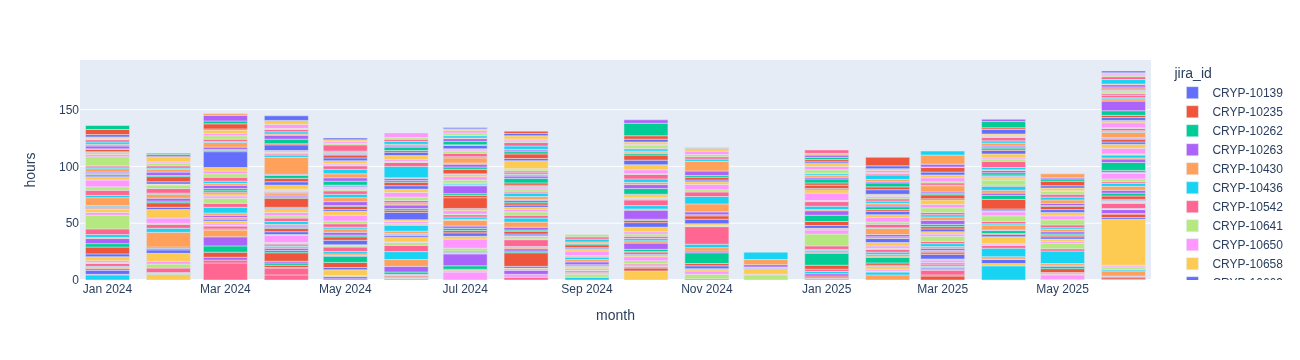

In [10]:
px.bar(user_issues_hours_monthly(ts_user).toPandas(),x='month',y='hours',color='jira_id',hover_data={'summary':True})

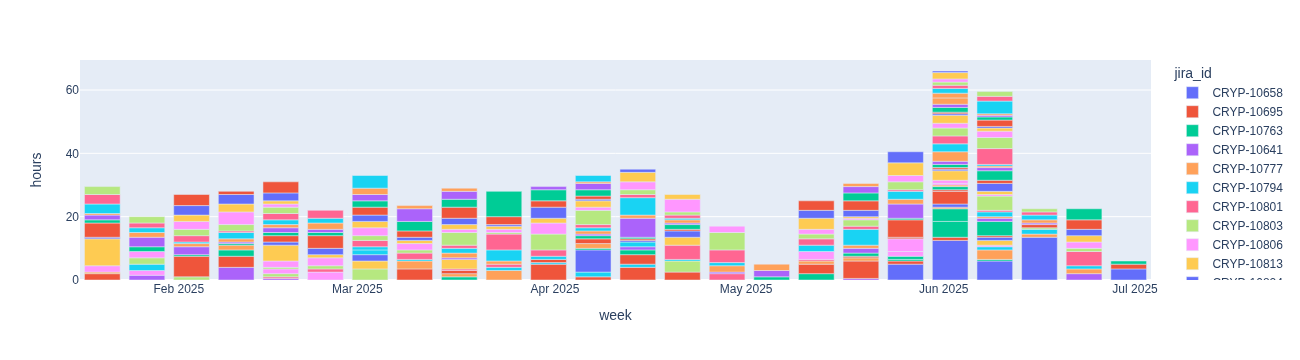

In [11]:
px.bar(user_issues_hours_weekly(ts_user).toPandas(),x='week',y='hours',color='jira_id',hover_data={'summary':True})

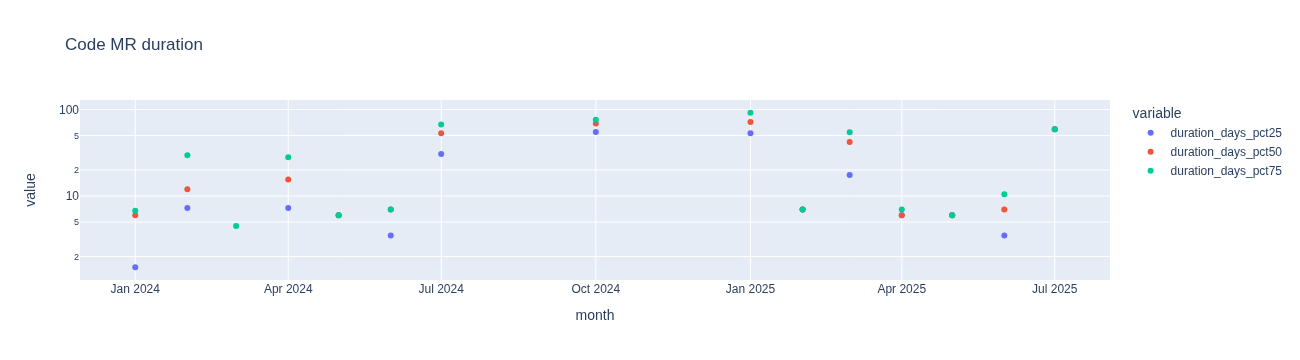

In [12]:
px.scatter(user_mrs_duration(gitlab_user).toPandas(),x='month',y=['duration_days_pct25','duration_days_pct50','duration_days_pct75'], log_y=True,title='Code MR duration')

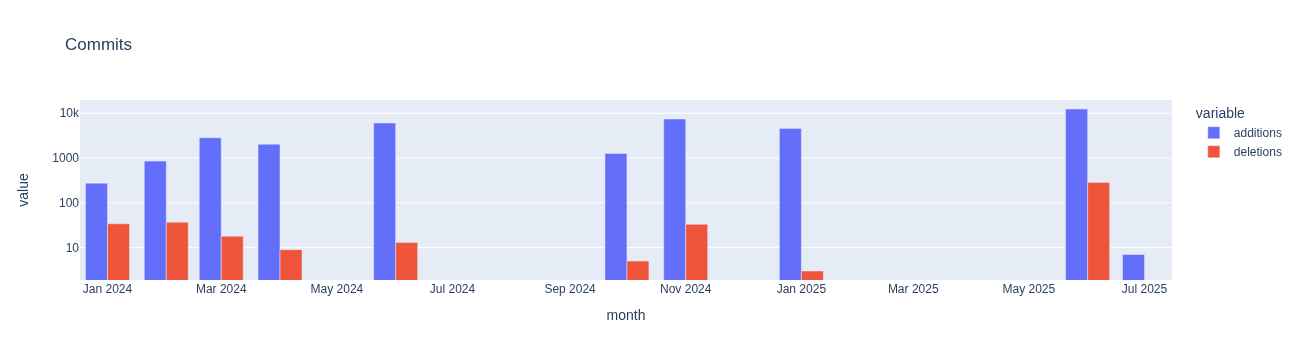

In [13]:
px.bar(user_code_commits(gitlab_user).toPandas(),x='month',y=['additions','deletions'],log_y=True,title='Commits',barmode='group')

In [14]:
users_hours.where(f.col('user')==ts_user).toPandas()

,month,user,jira_hours,other_hours,total_hours,other_hours_pct
0,2025-06-01,CWr,184.0,79.0,263.0,30.038023
1,2025-05-01,CWr,93.5,26.5,120.0,22.083333
2,2025-04-01,CWr,141.5,26.5,168.0,15.773810
3,2025-03-01,CWr,113.5,42.5,156.0,27.243590
4,2025-02-01,CWr,114.0,39.0,153.0,25.490196
5,2025-01-01,CWr,115.5,43.0,158.5,27.129338
6,2024-12-01,CWr,24.5,7.5,32.0,23.437500
7,2024-11-01,CWr,116.5,27.5,144.0,19.097222
8,2024-10-01,CWr,141.0,35.0,176.0,19.886364
9,2024-09-01,CWr,40.5,7.5,48.0,15.625000


In [15]:
user_other_hours(ts_user).toPandas()

,month,task_desc,other_hours
0,2025-06-01,backtesty,37.5
1,2025-06-01,spotkania projektowe zaplanowane,3.0
2,2025-06-01,spotkania 1:1,0.5
3,2025-06-01,"support, obsługa nagrywania",8.5
4,2025-06-01,spotkania firmowe,2.0
5,2025-06-01,"sprawdzanie, tworzenie MRów testów automatyczn...",1.0
6,2025-06-01,spotkania scrumowe,26.5
7,2025-05-01,"support, obsługa nagrywania",4.0
8,2025-05-01,spotkania projektowe zaplanowane,3.0
9,2025-05-01,spotkania scrumowe,17.0


----------------------------------------
Exception happened during processing of request from ('127.0.0.1', 58292)
Traceback (most recent call last):
  File "/usr/local/lib/python3.8/socketserver.py", line 316, in _handle_request_noblock
    self.process_request(request, client_address)
  File "/usr/local/lib/python3.8/socketserver.py", line 347, in process_request
    self.finish_request(request, client_address)
  File "/usr/local/lib/python3.8/socketserver.py", line 360, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "/usr/local/lib/python3.8/socketserver.py", line 747, in __init__
    self.handle()
  File "/home/daniel.las/work/workspace-crypto/warehouse/jupyterlab/venv/lib/python3.8/site-packages/pyspark/accumulators.py", line 262, in handle
    poll(accum_updates)
  File "/home/daniel.las/work/workspace-crypto/warehouse/jupyterlab/venv/lib/python3.8/site-packages/pyspark/accumulators.py", line 235, in poll
    if func():
  File "/home/daniel.l